### Check Python version

In [1]:
from platform import python_version_tuple

assert (
    python_version_tuple()[:2] == ("3", "11")
), "You are not running Python 3.11. Make sure to run Python through the course Conda environment."

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm
import tifffile as tiff

from convert_labels import from_rgb_labels_to_int_labels


## Playing around, testing image read and extractions

In [3]:
IMAGE_DIR = Path("potsdam/Ortho_RGB_small_train")
LABEL_DIR = Path("potsdam/Labels_all")

count=0
for i in IMAGE_DIR.glob("*.tif"):
    print (i)
    count+=1
print(f"Total number of images for training: {count}")

potsdam\Ortho_RGB_small_train\top_potsdam_2_10_RGB.tif
potsdam\Ortho_RGB_small_train\top_potsdam_2_12_RGB.tif
potsdam\Ortho_RGB_small_train\top_potsdam_4_10_RGB.tif
potsdam\Ortho_RGB_small_train\top_potsdam_5_11_RGB.tif
Total number of images for training: 4


In [4]:
sorted(IMAGE_DIR.glob("*.tif"))

[WindowsPath('potsdam/Ortho_RGB_small_train/top_potsdam_2_10_RGB.tif'),
 WindowsPath('potsdam/Ortho_RGB_small_train/top_potsdam_2_12_RGB.tif'),
 WindowsPath('potsdam/Ortho_RGB_small_train/top_potsdam_4_10_RGB.tif'),
 WindowsPath('potsdam/Ortho_RGB_small_train/top_potsdam_5_11_RGB.tif')]

Image path: potsdam\Ortho_RGB_small_train\top_potsdam_4_10_RGB.tif
Label path: potsdam\Labels_all\top_potsdam_4_10_label.tif 

Image shape: (6000, 6000, 3)
Label shape: (6000, 6000, 3) 

Class of image: <class 'numpy.ndarray'>
Class of label: <class 'numpy.ndarray'> 

Image dtype: uint8
Label dtype: uint8


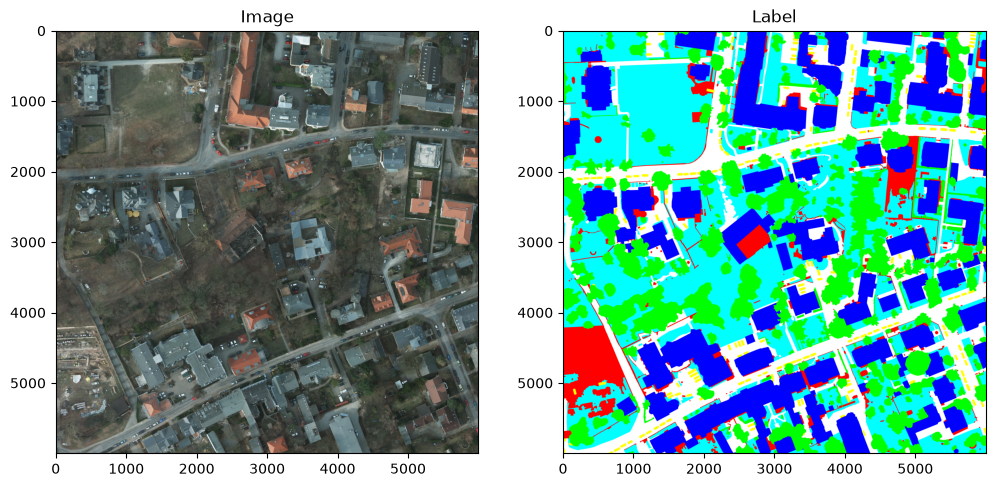

In [5]:
image_path = sorted(IMAGE_DIR.glob("*.tif"))[2]

label_path = LABEL_DIR / image_path.name.replace("_RGB", "_label")

print(f"Image path: {image_path}")
print(f"Label path: {label_path} \n")


image = tiff.imread(image_path)
label = tiff.imread(label_path)


print(f"Image shape: {image.shape}")
print(f"Label shape: {label.shape} \n")

print(f"Class of image: {type(image)}")
print(f"Class of label: {type(label)} \n")

print(f"Image dtype: {image.dtype}")
print(f"Label dtype: {label.dtype}")


plt.subplots(1, 2, figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Image")

plt.subplot(1, 2, 2)
plt.imshow(label)
plt.title("Label")
plt.show()

In [6]:
label_int = from_rgb_labels_to_int_labels(label)
value_counts = np.unique(label_int, return_counts=True)

print(f"Label shape: {label_int.shape}")
print(f"labels: {value_counts[0]}")
print(f"labels counts: {value_counts[1]}")
print(f"proportions: {(np.bincount(label_int.flatten())) / label_int.size}")

Label shape: (6000, 6000)
labels: [0 1 2 3 4 5]
labels counts: [ 6806382  8658500 10730811  7147886   469987  2186434]
proportions: [0.18906617 0.24051389 0.29807808 0.19855239 0.01305519 0.06073428]


# EXTRACTION OF IMAGES STARTS HERE

- from each original image tile (6000 x 6000 x 3)
    - we will extract patches of size (512 x 512 x 3)
    - `stride = 256` therefore, the neighboring patches will overlap by half

- To be able to use all pixels from the original image tiles
    - A last index corresponding to 6000-512 will be manually added
    - in order to cover the rightmost part and the bottom part of each original image tile

In [7]:
print(image_path.name)
print(image_path.stem)
print((image_path.stem).replace("_RGB", ""))


top_potsdam_4_10_RGB.tif
top_potsdam_4_10_RGB
top_potsdam_4_10


## OBS!

### Creating `small_train` using the extraction test data with only 4 images tiles a (6000 x 6000)

In [8]:
# =====================================================
# CONFIGURATION
# =====================================================

IMAGE_DIR = Path("potsdam/Ortho_RGB_small_train")
LABEL_DIR = Path("potsdam/Labels_all")

OUT_IMAGE_DIR = Path("small_train_patches/images")
OUT_LABEL_DIR = Path("small_train_patches/labels")

PATCH_SIZE = 512
STRIDE = 256  # 512 = no overlap

OUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUT_LABEL_DIR.mkdir(parents=True, exist_ok=True)

In [9]:
# =====================================================
# EXTRACTION
# =====================================================

image_files = sorted(IMAGE_DIR.glob("*.tif"))

for image_path in tqdm(image_files):

    # Labels have same name as image with ending "_RGB" replaced with "_label")
    label_path = LABEL_DIR / image_path.name.replace("_RGB", "_label")

    if not label_path.exists():
        print(f"Missing label for {image_path.name}")
        continue

    image = tiff.imread(image_path)
    label = tiff.imread(label_path)

    # shape of image read using tifffile is (H, W, C) 
    # for Potsdam images, this is== (6000, 6000, 3) 
    h, w = image.shape[0], image.shape[1]


    stem = (image_path.stem).replace("_RGB", "")

    patch_count = 0
    skip_count = 0

    # Calculate the x and y starting coordinates of the patches
    xs = list(range(0, w - PATCH_SIZE, STRIDE))
    ys = list(range(0, h - PATCH_SIZE, STRIDE))

    # Ensure that the last patch along x-axis includes the rightmost part of the image
    if xs[-1] != w - PATCH_SIZE:
        xs.append(w - PATCH_SIZE)

    # Ensure that the last patch along y-axis includes the bottom edge of the image
    if ys[-1] != h - PATCH_SIZE:
        ys.append(h - PATCH_SIZE)

    
    for y in ys:
        for x in xs:

            image_patch = image[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE ]

            label_patch = label[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE ]


            # create a new label patch with integer labels {0,1,2,3,4,5} instead of RGB values
            label_patch_int = from_rgb_labels_to_int_labels(label_patch)

            # Calculate the fraction of the patch that belongs to the majority class
            majority_fraction = np.max(np.bincount(label_patch_int.flatten())) / label_patch_int.size


            # If the majority class occupies more than 95% of the patch, skip this patch
            # i.e. if the patch is highly uniform, we skip it
            if majority_fraction > 0.95:
                skip_count += 1
                continue

            
            patch_name = f"{stem}_{y}_{x}.tif"

            tiff.imwrite(
                OUT_IMAGE_DIR / patch_name,
                image_patch )

            tiff.imwrite(
                OUT_LABEL_DIR / patch_name,
                label_patch )

            patch_count += 1

    print(f"From image tile {image_path.name}: {patch_count} patches extracted, {skip_count} patches skipped due to majority class > 95%")

print("Finished.")

 25%|██▌       | 1/4 [00:18<00:54, 18.03s/it]

From image tile top_potsdam_2_10_RGB.tif: 505 patches extracted, 24 patches skipped due to majority class > 95%


 50%|█████     | 2/4 [00:36<00:36, 18.27s/it]

From image tile top_potsdam_2_12_RGB.tif: 475 patches extracted, 54 patches skipped due to majority class > 95%


 75%|███████▌  | 3/4 [00:55<00:18, 18.73s/it]

From image tile top_potsdam_4_10_RGB.tif: 521 patches extracted, 8 patches skipped due to majority class > 95%


100%|██████████| 4/4 [01:14<00:00, 18.61s/it]

From image tile top_potsdam_5_11_RGB.tif: 528 patches extracted, 1 patches skipped due to majority class > 95%
Finished.
